# AI4I Predictive Maintenance Dataset Analsis

## Overview

This notebook performs an initial exploration of the raw predictive
maintenance dataset before data cleaning, transformation, or modeling.

The objectives are to:

- Understand the structure and size of the dataset
- Review variable names and data types
- Identify missing values and duplicate records
- Examine categorical variables
- Review distributions of numeric variables
- Examine machine failure frequencies
- Identify potential data-quality issues and outliers
- Document observations that will guide data cleaning

## 1. Imports and display settings

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## 2. Load the raw data

In [2]:
file_path = "../../data/raw/ai4i2020.csv"

df_raw = pd.read_csv(file_path)

df_raw.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df_raw.sample(5, random_state=99)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
7653,7654,L54833,L,300.4,311.5,1492,44.6,149,0,0,0,0,0,0
7865,7866,L55045,L,300.5,311.9,1383,50.5,35,0,0,0,0,0,0
3226,3227,L50406,L,300.5,309.3,1465,46.0,89,0,0,0,0,0,0
5912,5913,M20772,M,300.7,310.3,1659,29.8,6,0,0,0,0,0,0
8237,8238,L55417,L,299.1,310.6,1796,26.0,90,0,0,0,0,0,0


## 3. Initial inspection

In [4]:
print("Shape:", df_raw.shape)

display(df_raw.head())

df_raw.info()

Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

## 4. Column Names

In [5]:
df_raw.columns.tolist()

['UDI',
 'Product ID',
 'Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]',
 'Machine failure',
 'TWF',
 'HDF',
 'PWF',
 'OSF',
 'RNF']

## 5. Data types

In [6]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9), str(2)
me

In [7]:
df_raw.dtypes

UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

- Identifiers: UDI, Product ID
- Categorical: Type
- Numeric Measurements: Air temperature, Process temperature, Rotational speed, Torque, Tool wear
Binary Indicators: Machine failure, TWF, HDF, PWF, OSF, RNF

## 6. Descriptive Statistics

In [9]:
df_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
UDI,10000.0,NaN,NaN,NaN,5000.5,2886.89568,1.0,2500.75,5000.5,7500.25,10000.0
Product ID,10000,10000,M14860,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature [K],10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0


Statistics show that there are 10,000 observations.

In [10]:
df_raw[
    [
        "Air temperature [K]",
        "Process temperature [K]",
        "Rotational speed [rpm]",
        "Torque [Nm]",
        "Tool wear [min]"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
Air temperature [K],10000.0,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature [K],10000.0,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed [rpm],10000.0,1538.77610,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque [Nm],10000.0,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear [min],10000.0,107.95100,63.654147,0.0,53.0,108.0,162.0,253.0


Removed identifiers and indicators for a cleaner view of numeric statistics.

## 7. Missing Values

In [11]:
missing = pd.DataFrame({
    "Missing_Count": df_raw.isna().sum(),
    "Missing_Percent": df_raw.isna().mean() * 100
})

missing

,Missing_Count,Missing_Percent
UDI,0,0.0
Product ID,0,0.0
Type,0,0.0
Air temperature [K],0,0.0
Process temperature [K],0,0.0
Rotational speed [rpm],0,0.0
Torque [Nm],0,0.0
Tool wear [min],0,0.0
Machine failure,0,0.0
TWF,0,0.0


No missing values in dataset.

## 8. Duplicate Records

In [12]:
print("Duplicate rows:", df_raw.duplicated().sum())

Duplicate rows: 0


No duplicate records in dataset.

In [13]:
print("Unique UDI:", df_raw["UDI"].nunique())
print("Unique Product IDs:", df_raw["Product ID"].nunique())

Unique UDI: 10000
Unique Product IDs: 10000


10,000 unique observations.

## 9. Explore types

In [14]:
df_raw["Type"].value_counts()

Type
L    6000
M    2997
H    1003
Name: count, dtype: int64

In [15]:
df_raw["Type"].value_counts(normalize=True) * 100

Type
L    60.00
M    29.97
H    10.03
Name: proportion, dtype: float64

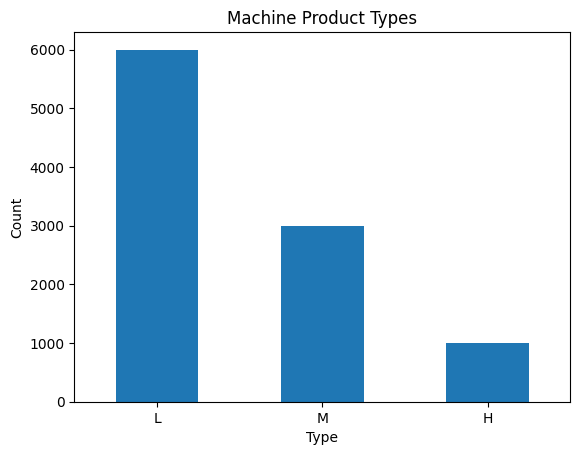

In [35]:
df_raw["Type"].value_counts().plot(kind="bar")

plt.title("Machine Product Types")
plt.xlabel("Type")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.show()

## 10. Explore Numeric Features

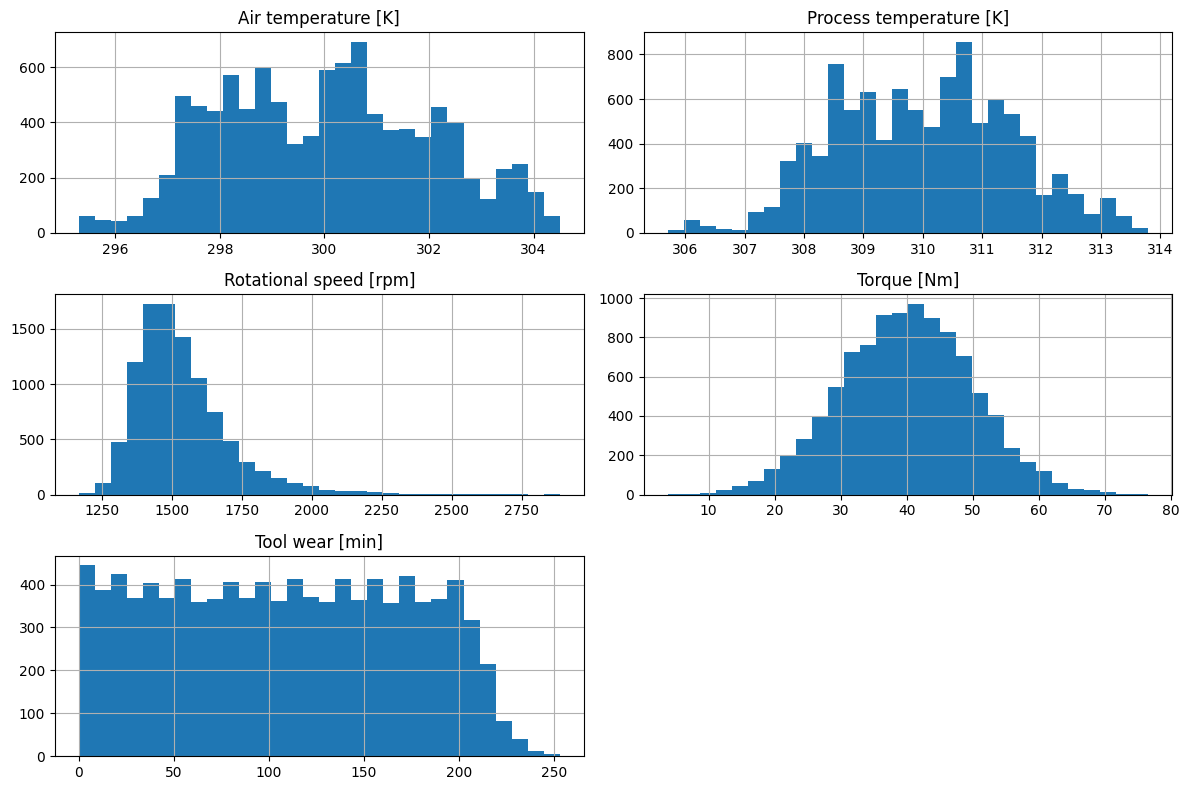

In [17]:
numeric_features = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

df_raw[numeric_features].hist(
    bins=30,
    figsize=(12, 8)
)

plt.tight_layout()
plt.show()

## 11. Explore outliers

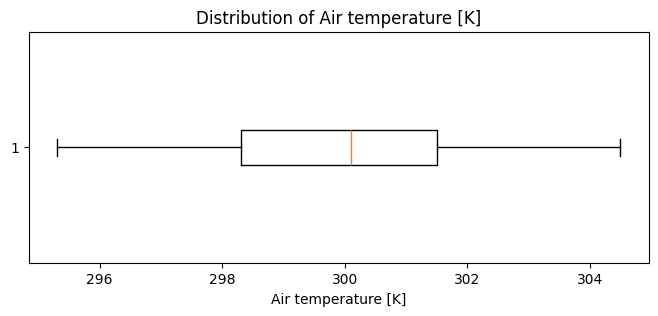

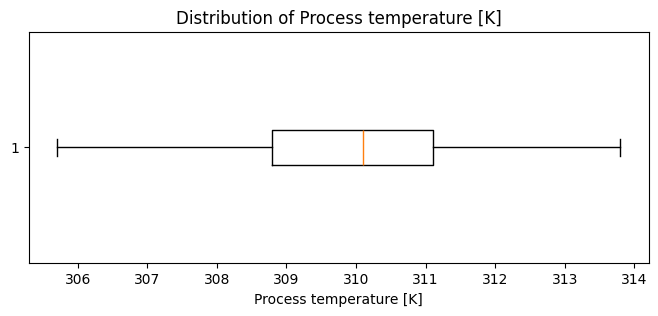

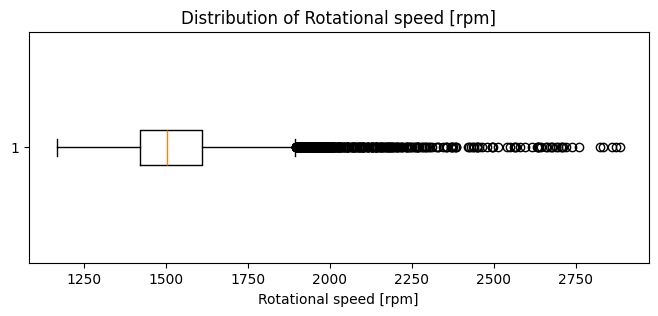

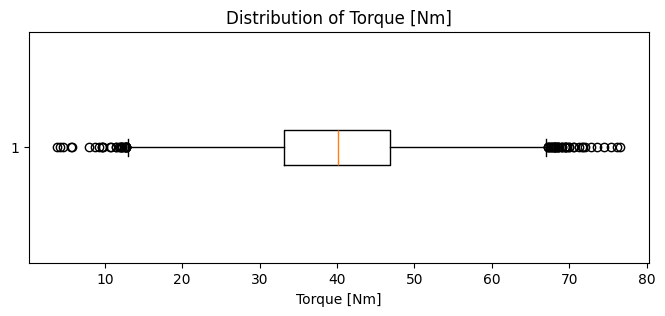

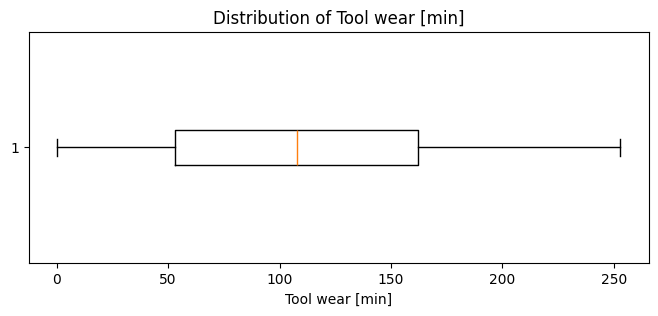

In [18]:
for col in numeric_features:
    plt.figure(figsize=(8, 3))
    plt.boxplot(df_raw[col], vert=False)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.show()

## 12. Examine machine failures

In [19]:
df_raw["Machine failure"].value_counts()

Machine failure
0    9661
1     339
Name: count, dtype: int64

In [20]:
df_raw["Machine failure"].value_counts(normalize=True) * 100

Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

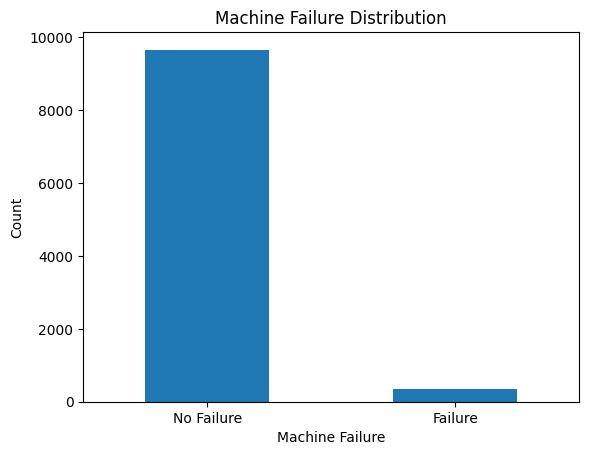

In [39]:
df_raw["Machine failure"].value_counts().plot(kind="bar")

plt.title("Machine Failure Distribution")
plt.xlabel("Machine Failure")
plt.ylabel("Count")
plt.xticks([0, 1], ["No Failure", "Failure"], rotation=0)
plt.show()

## 13. Examine failure types

In [40]:
failure_cols = [
    "TWF",
    "HDF",
    "PWF",
    "OSF",
    "RNF"
]

failure_summary = pd.DataFrame({
    "Count": df_raw[failure_cols].sum(),
    "Percent": df_raw[failure_cols].mean() * 100
})

failure_summary

,Count,Percent
TWF,46,0.46
HDF,115,1.15
PWF,95,0.95
OSF,98,0.98
RNF,19,0.19


## 14. Examine failure realtionships.

In [41]:
failure_count = df_raw[failure_cols].sum(axis=1)

failure_count.value_counts().sort_index()

0    9652
1     324
2      23
3       1
Name: count, dtype: int64

In [42]:
any_failure = df_raw[failure_cols].max(axis=1)

pd.crosstab(
    df_raw["Machine failure"],
    any_failure,
    rownames=["Machine failure"],
    colnames=["Any failure flag"]
)

Any failure flag,0,1
Machine failure,,
0,9643,18
1,9,330


18 Observations show a individual failure flag, but Machine failure is false.
9 Observations show a Machine failure, but no individual failure flags are true.